## PLOTING RESULT

### RQ1: FALCON vs FAST Effectiveness

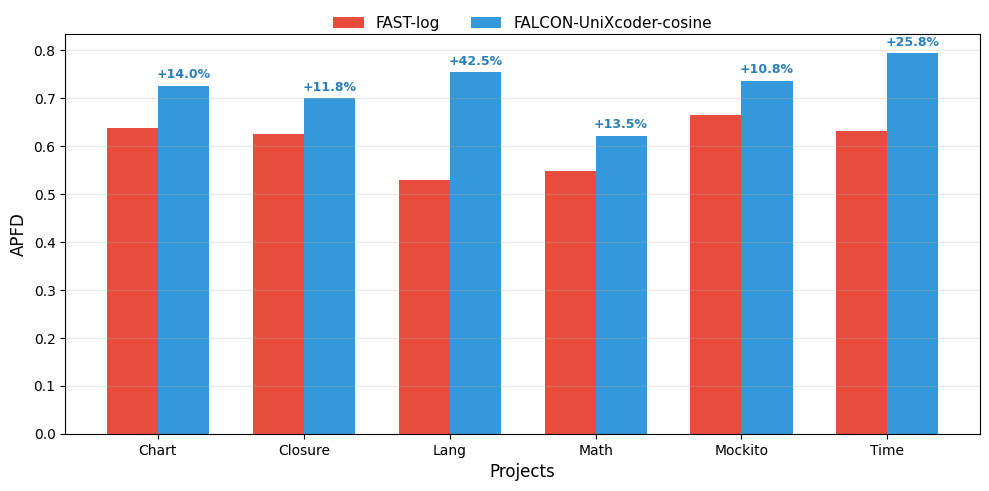

In [38]:
import matplotlib.pyplot as plt
import numpy as np

projects = ['Chart', 'Closure', 'Lang', 'Math', 'Mockito', 'Time']
fast_log = [0.637, 0.626, 0.529, 0.548, 0.664, 0.631]
falcon_unixcoder = [0.726, 0.700, 0.754, 0.622, 0.736, 0.794]

x = np.arange(len(projects))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
bars1 = ax.bar(x - width/2, fast_log, width, label='FAST-log', color='#E74C3C')
bars2 = ax.bar(x + width/2, falcon_unixcoder, width, label='FALCON-UniXcoder-cosine', color='#3498DB')

ax.set_xlabel('Projects', fontsize=12)
ax.set_ylabel('APFD', fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(projects)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, 1.08), ncol=2, frameon=False, fontsize=11)
ax.grid(axis='y', alpha=0.3)

# Add improvement percentages above bars
for i, (f, falcon) in enumerate(zip(fast_log, falcon_unixcoder)):
    improvement = ((falcon - f) / f) * 100
    ax.text(i + width/2, falcon + 0.01, f'+{improvement:.1f}%', 
            ha='center', va='bottom', fontsize=9, color='#2980B9', fontweight='bold')

plt.tight_layout()
plt.savefig('plots/rq1_per_project_comparison.pdf', dpi=300, bbox_inches='tight')
plt.show()

### RQ2: Runtime vs Effectiveness Trade-off

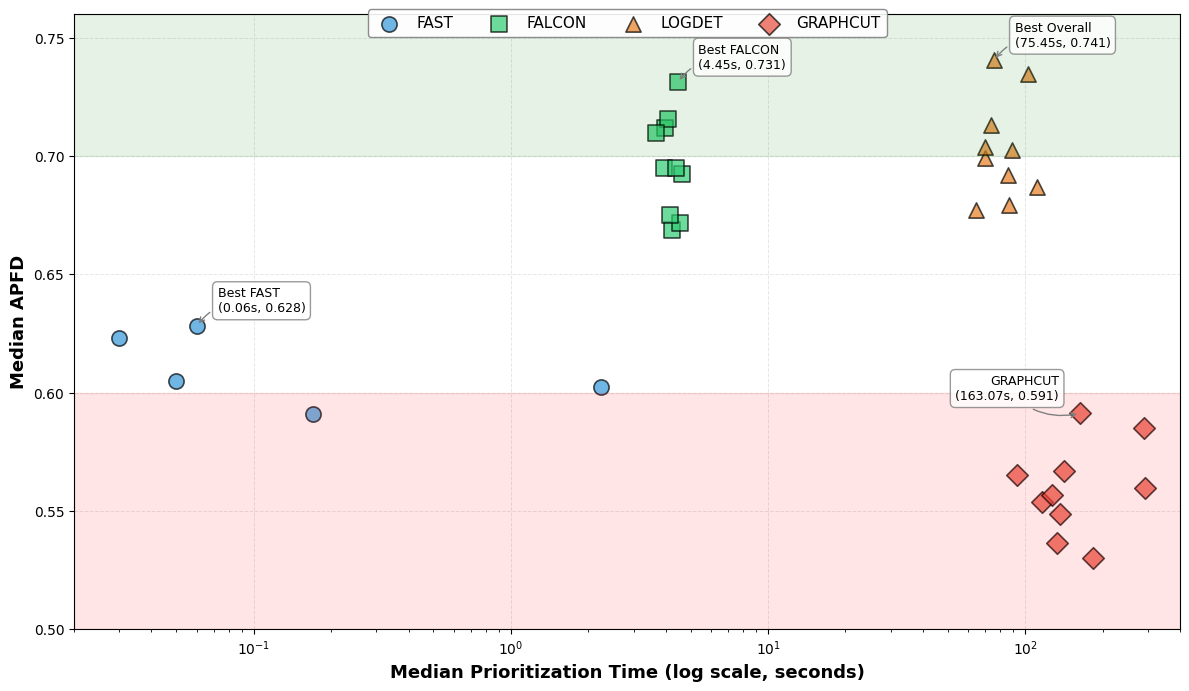

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Comprehensive data extracted from the results table
# Format: (method_family, method_name, avg_runtime, median_apfd)
data = [
    # FAST methods
    ('FAST', 'FAST-all', 0.03, 0.6232),
    ('FAST', 'FAST-log', 0.06, 0.6283),
    ('FAST', 'FAST-one', 0.17, 0.5911),
    ('FAST', 'FAST-pw', 2.25, 0.6024),
    ('FAST', 'FAST-sqrt', 0.05, 0.6050),
    
    # FALCON methods
    ('FALCON', 'FALCON-CodeBERT-cosine', 4.64, 0.6926),
    ('FALCON', 'FALCON-CodeBERT-euclidean', 4.25, 0.6689),
    ('FALCON', 'FALCON-CodeXEmbed-cosine', 3.98, 0.7120),
    ('FALCON', 'FALCON-CodeXEmbed-euclidean', 3.94, 0.6949),
    ('FALCON', 'FALCON-GraphCodeBERT-cosine', 4.54, 0.6716),
    ('FALCON', 'FALCON-GraphCodeBERT-euclidean', 4.14, 0.6752),
    ('FALCON', 'FALCON-StarEncoder-cosine', 4.37, 0.6948),
    ('FALCON', 'FALCON-StarEncoder-euclidean', 4.09, 0.7157),
    ('FALCON', 'FALCON-UniXcoder-cosine', 4.45, 0.7313),
    ('FALCON', 'FALCON-UniXcoder-euclidean', 3.68, 0.7097),
    
    # LOGDET methods
    ('LOGDET', 'LOGDET-CodeBERT-cosine', 64.15, 0.6770),
    ('LOGDET', 'LOGDET-CodeBERT-euclidean', 85.93, 0.6918),
    ('LOGDET', 'LOGDET-CodeXEmbed-cosine', 102.85, 0.7349),
    ('LOGDET', 'LOGDET-CodeXEmbed-euclidean', 75.45, 0.7406),
    ('LOGDET', 'LOGDET-GraphCodeBERT-cosine', 69.55, 0.6992),
    ('LOGDET', 'LOGDET-GraphCodeBERT-euclidean', 86.21, 0.6794),
    ('LOGDET', 'LOGDET-StarEncoder-cosine', 69.51, 0.7040),
    ('LOGDET', 'LOGDET-StarEncoder-euclidean', 73.71, 0.7133),
    ('LOGDET', 'LOGDET-UniXcoder-cosine', 89.10, 0.7024),
    ('LOGDET', 'LOGDET-UniXcoder-euclidean', 110.74, 0.6869),
    
    # GRAPHCUT methods
    ('GRAPHCUT', 'GRAPHCUT-CodeBERT-cosine', 184.20, 0.5299),
    ('GRAPHCUT', 'GRAPHCUT-CodeBERT-euclidean', 115.94, 0.5538),
    ('GRAPHCUT', 'GRAPHCUT-CodeXEmbed-cosine', 163.07, 0.5912),
    ('GRAPHCUT', 'GRAPHCUT-CodeXEmbed-euclidean', 289.70, 0.5852),
    ('GRAPHCUT', 'GRAPHCUT-GraphCodeBERT-cosine', 136.17, 0.5486),
    ('GRAPHCUT', 'GRAPHCUT-GraphCodeBERT-euclidean', 127.41, 0.5568),
    ('GRAPHCUT', 'GRAPHCUT-StarEncoder-cosine', 291.24, 0.5596),
    ('GRAPHCUT', 'GRAPHCUT-StarEncoder-euclidean', 133.11, 0.5364),
    ('GRAPHCUT', 'GRAPHCUT-UniXcoder-cosine', 92.64, 0.5650),
    ('GRAPHCUT', 'GRAPHCUT-UniXcoder-euclidean', 141.44, 0.5669),
]

# Convert to DataFrame for easier manipulation
df = pd.DataFrame(data, columns=['family', 'method', 'runtime', 'apfd'])

# Define colors and markers for each family
colors = {
    'FAST': '#3498db',
    'FALCON': '#2ecc71',
    'LOGDET': '#e67e22',
    'GRAPHCUT': '#e74c3c',
}

markers = {
    'FAST': 'o',
    'FALCON': 's',
    'LOGDET': '^',
    'GRAPHCUT': 'D',
}

# Create the plot
fig, ax = plt.subplots(figsize=(12, 7))

# Plot each family
for family in ['FAST', 'FALCON', 'LOGDET', 'GRAPHCUT']:
    family_data = df[df['family'] == family]
    ax.scatter(family_data['runtime'], family_data['apfd'], 
              s=120, alpha=0.7, color=colors[family], 
              marker=markers[family], label=family, 
              edgecolors='black', linewidth=1.2)

# Set log scale for x-axis
ax.set_xscale('log')

# Labels (no title)
ax.set_xlabel('Median Prioritization Time (log scale, seconds)', fontsize=13, fontweight='bold')
ax.set_ylabel('Median APFD', fontsize=13, fontweight='bold')

# Legend - horizontal at top
ax.legend(loc='upper center', frameon=True, fontsize=11, 
         framealpha=0.9, edgecolor='gray', ncol=4, bbox_to_anchor=(0.5, 1.02))

# Grid
ax.grid(True, alpha=0.3, linestyle='--', linewidth=0.7)
ax.set_axisbelow(True)

# Annotate best performers from each family
annotations = [
    ('FAST-log', 0.06, 0.6283, 'Best FAST\n(0.06s, 0.628)', 'left'),
    ('FALCON-UniXcoder-cosine', 4.45, 0.7313, 'Best FALCON\n(4.45s, 0.731)', 'left'),
    ('LOGDET-CodeXEmbed-euclidean', 75.45, 0.7406, 'Best Overall\n(75.45s, 0.741)', 'left'),
    ('GRAPHCUT-CodeXEmbed-cosine', 163.07, 0.5912, 'GRAPHCUT\n(163.07s, 0.591)', 'right'),
]

for method, x, y, text, ha in annotations:
    ax.annotate(text, xy=(x, y), 
               xytext=(15 if ha == 'left' else -15, 10),
               textcoords='offset points', 
               fontsize=9,
               ha=ha,
               bbox=dict(boxstyle='round,pad=0.4', facecolor='white', 
                        edgecolor='gray', alpha=0.8),
               arrowprops=dict(arrowstyle='->', connectionstyle='arc3,rad=0.3',
                             color='gray', lw=1))

# Add a Pareto frontier line to show trade-off
pareto_data = []
for family in df['family'].unique():
    best = df[df['family'] == family].sort_values('apfd', ascending=False).iloc[0]
    pareto_data.append((best['runtime'], best['apfd']))

pareto_data.sort(key=lambda x: x[0])
pareto_x, pareto_y = zip(*pareto_data)

# Set axis limits with some padding
ax.set_ylim(0.50, 0.76)
ax.set_xlim(0.02, 400)

# Add subtle background regions
ax.axhspan(0.70, 0.76, alpha=0.1, color='green', label='High Effectiveness (>0.70)')
ax.axhspan(0.50, 0.60, alpha=0.1, color='red', label='Low Effectiveness (<0.60)')

plt.tight_layout()
plt.savefig('plots/rq2_runtime_vs_apfd.pdf', 
            dpi=300, bbox_inches='tight')
plt.show()

### RQ3: Embedding Model Impact

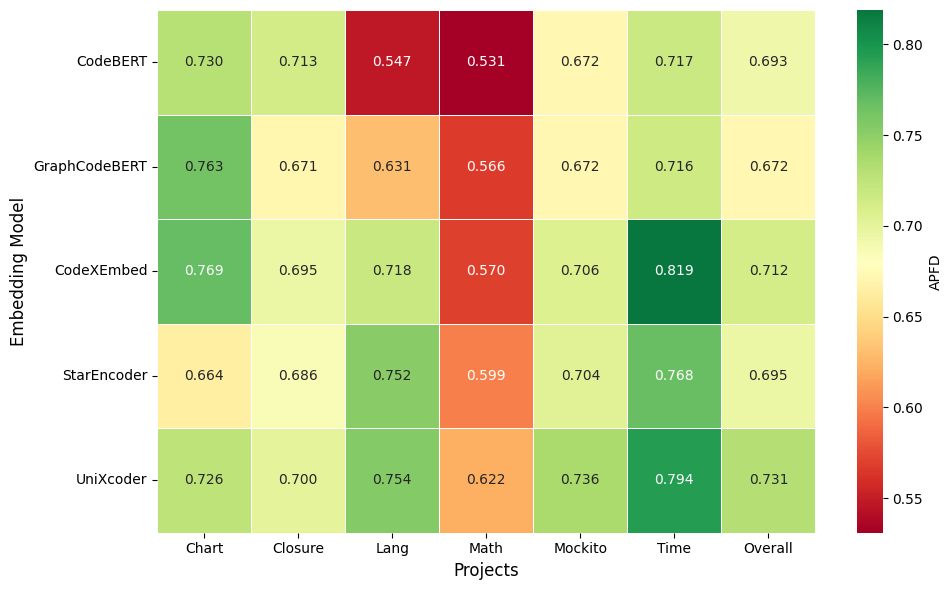

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# Data: FALCON with cosine similarity
data = {
    'CodeBERT': [0.730, 0.713, 0.547, 0.531, 0.672, 0.717, 0.693],
    'GraphCodeBERT': [0.763, 0.671, 0.631, 0.566, 0.672, 0.716, 0.672],
    'CodeXEmbed': [0.769, 0.695, 0.718, 0.570, 0.706, 0.819, 0.712],
    'StarEncoder': [0.664, 0.686, 0.752, 0.599, 0.704, 0.768, 0.695],
    'UniXcoder': [0.726, 0.700, 0.754, 0.622, 0.736, 0.794, 0.731]
}

projects = ['Chart', 'Closure', 'Lang', 'Math', 'Mockito', 'Time', 'Overall']
df = pd.DataFrame(data, index=projects).T

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(df, annot=True, fmt='.3f', cmap='RdYlGn', center=0.68, 
            linewidths=0.5, cbar_kws={'label': 'APFD'}, ax=ax)
# ax.set_title('FALCON Effectiveness by Embedding Model and Project (Cosine Similarity)', fontsize=14)
ax.set_xlabel('Projects', fontsize=12)
ax.set_ylabel('Embedding Model', fontsize=12)

plt.tight_layout()
plt.savefig('plots/rq3_embedding_heatmap.pdf', dpi=300, bbox_inches='tight')
plt.show()

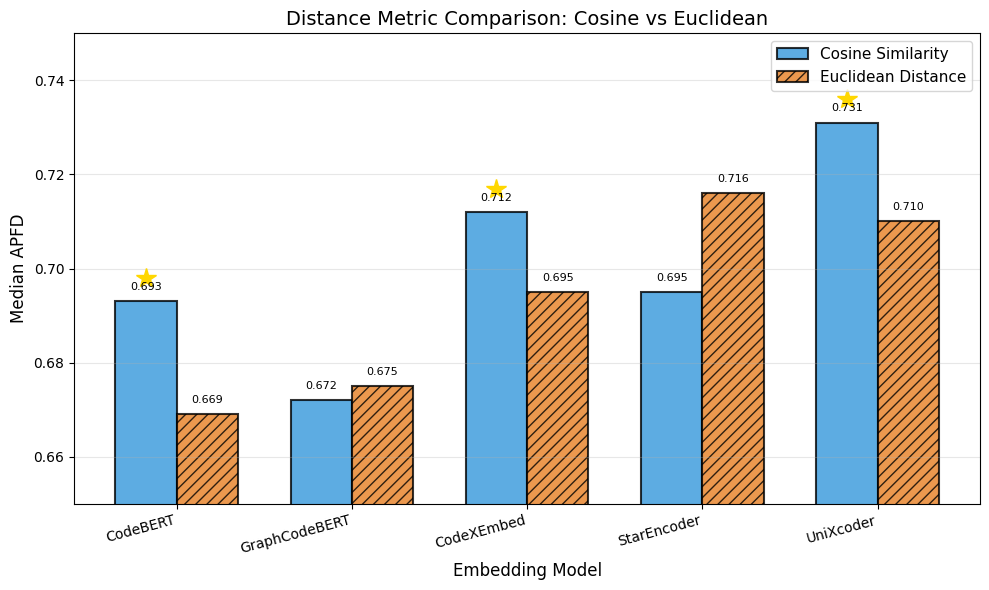

In [3]:
import matplotlib.pyplot as plt
import numpy as np

embeddings = ['CodeBERT', 'GraphCodeBERT', 'CodeXEmbed', 'StarEncoder', 'UniXcoder']
cosine_apfd = [0.693, 0.672, 0.712, 0.695, 0.731]
euclidean_apfd = [0.669, 0.675, 0.695, 0.716, 0.710]

x = np.arange(len(embeddings))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

bars1 = ax.bar(x - width/2, cosine_apfd, width, label='Cosine Similarity', 
               color='#3498db', alpha=0.8, edgecolor='black', linewidth=1.5)
bars2 = ax.bar(x + width/2, euclidean_apfd, width, label='Euclidean Distance', 
               color='#e67e22', alpha=0.8, edgecolor='black', linewidth=1.5, hatch='///')

ax.set_xlabel('Embedding Model', fontsize=12)
ax.set_ylabel('Median APFD', fontsize=12)
ax.set_title('Distance Metric Comparison: Cosine vs Euclidean', fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels(embeddings, rotation=15, ha='right')
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.3)
ax.set_ylim([0.65, 0.75])

# Add value labels on bars
for bar in bars1:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 0.002,
            f'{height:.3f}', ha='center', va='bottom', fontsize=8)

for bar in bars2:
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2., height + 0.002,
            f'{height:.3f}', ha='center', va='bottom', fontsize=8)

# Highlight which is better
for i, (cos, euc) in enumerate(zip(cosine_apfd, euclidean_apfd)):
    if cos > euc:
        ax.plot([i - width/2], [cos + 0.005], marker='*', color='gold', markersize=15)

plt.tight_layout()
plt.savefig('plots/rq3_cosine_vs_euclidean.pdf', dpi=300, bbox_inches='tight')
plt.show()